<a href="https://colab.research.google.com/github/SalmaAnindhia/PemMes_25_Salma/blob/main/JS10/JS10_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 - Import Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

## Langkah 2 - Load Dataset

In [2]:
(X_train_img, y_train_all), (X_test_img, y_test) = tf.keras.datasets.mnist.load_data()

print("Data latih:", X_train_img.shape, y_train_all.shape)
print("Data test :", X_test_img.shape, y_test.shape)
print("Kelas     :", np.unique(y_train_all))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Data latih: (60000, 28, 28) (60000,)
Data test : (10000, 28, 28) (10000,)
Kelas     : [0 1 2 3 4 5 6 7 8 9]


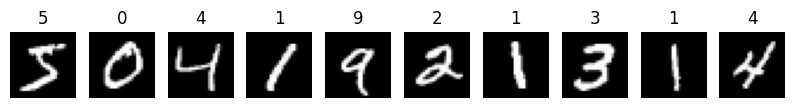

In [3]:
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train_img[i], cmap='gray')
    plt.title(y_train_all[i])
    plt.axis('off')
plt.show()

## Langkah 3 - Pra Pengolahan


In [4]:
def preprocess(X_imgs):
    X = X_imgs.astype('float32') / 255.0
    return X.reshape(len(X), -1)   # 28x28 -> 784

X_train_pix = preprocess(X_train_img)
X_test_pix  = preprocess(X_test_img)

print(X_train_pix.shape, X_test_pix.shape)

(60000, 784) (10000, 784)


## Langkah 4 - Ekstraksi Fitur (HOG)

In [5]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        hog_feat = hog(img,
                       orientations=9,
                       pixels_per_cell=(7, 7),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_hog = extract_hog(X_train_img)
X_test_hog  = extract_hog(X_test_img)

print(X_train_hog.shape, X_test_hog.shape)

(60000, 324) (10000, 324)


## Langkah 5 - Standardisasi Fitur HOG

In [6]:
scaler = StandardScaler()
X_train_hog_s = scaler.fit_transform(X_train_hog)
X_test_hog_s  = scaler.transform(X_test_hog)

## Langkah 6 - Buat Data Latih dan Validasi

In [7]:
idx = np.arange(len(y_train_all))
idx_tr, idx_val = train_test_split(idx, test_size=0.2, random_state=42, stratify=y_train_all)

y_train = y_train_all[idx_tr]
y_val   = y_train_all[idx_val]

# Fitur piksel mentah
Xp_train, Xp_val = X_train_pix[idx_tr], X_train_pix[idx_val]

# Fitur HOG
Xh_train, Xh_val = X_train_hog_s[idx_tr], X_train_hog_s[idx_val]

print("Train:", Xp_train.shape, "| Val:", Xp_val.shape, "| Test:", X_test_pix.shape)

Train: (48000, 784) | Val: (12000, 784) | Test: (10000, 784)


## Langkah 7 - Buat Model ANN


In [8]:
def build_model(input_dim, hidden=(128, 64), activation='relu', dropout=0.0):
    m = models.Sequential()
    m.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        m.add(layers.Dense(units, activation=activation))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation='softmax'))
    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

model = build_model(Xp_train.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 8 - Latih Model

In [9]:
history = model.fit(
    Xp_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(Xp_val, y_val)
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8967 - loss: 0.3721 - val_accuracy: 0.9409 - val_loss: 0.1982
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9556 - loss: 0.1518 - val_accuracy: 0.9571 - val_loss: 0.1446
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9687 - loss: 0.1053 - val_accuracy: 0.9663 - val_loss: 0.1136
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9752 - loss: 0.0811 - val_accuracy: 0.9673 - val_loss: 0.1043
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9812 - loss: 0.0625 - val_accuracy: 0.9703 - val_loss: 0.1004
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9839 - loss: 0.0515 - val_accuracy: 0.9713 - val_loss: 0.0954
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9867 - loss: 0.0428 - val_accuracy: 0.9732 - val_loss: 0.0967
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9906 - loss: 0.0325 - val_accuracy: 0.

## Langkah 9 - Evaluasi Model dengan Data Test

In [10]:
test_loss, test_acc = model.evaluate(X_test_pix, y_test)
print("Akurasi Test:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9755 - loss: 0.1195
Akurasi Test: 0.9754999876022339


## Langkah 10 - Buat Laporan Performansi Model

In [11]:
y_pred_prob = model.predict(X_test_pix)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(y_test, y_pred, digits=4))
print(confusion_matrix(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0     0.9672    0.9939    0.9804       980
           1     0.9869    0.9930    0.9899      1135
           2     0.9702    0.9787    0.9744      1032
           3     0.9623    0.9851    0.9736      1010
           4     0.9795    0.9735    0.9765       982
           5     0.9808    0.9753    0.9781       892
           6     0.9802    0.9802    0.9802       958
           7     0.9859    0.9523    0.9688      1028
           8     0.9651    0.9661    0.9656       974
           9     0.9767    0.9554    0.9659      1009

    accuracy                         0.9755     10000
   macro avg     0.9755    0.9754    0.9753     10000
weighted avg     0.9756    0.9755    0.9755     10000

[[ 974    1    0    0    0    0    1    1    3    0]
 [   0 1127    2    2    0    0    2    1    1    0]
 [   7    0 1010    3    2    1    1    2    6    0]
 [   0    0    4  995    0    4    0    2

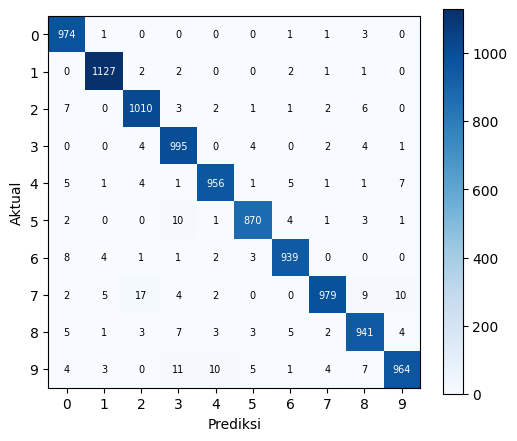

In [12]:
# Confusion matrix dalam bentuk gambar
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.xticks(range(10)); plt.yticks(range(10))
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=7)
plt.show()

## Langkah 11 - Visualisasi Proses Training

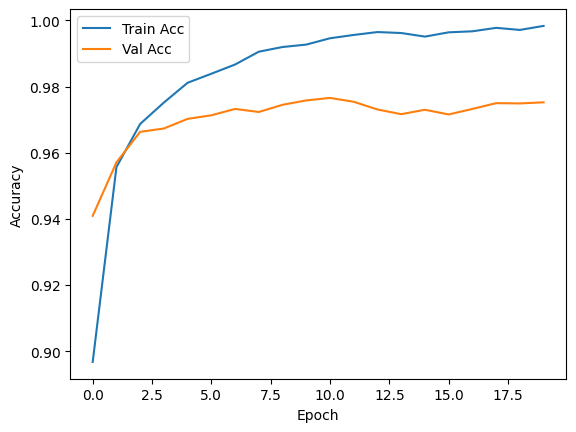

In [13]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

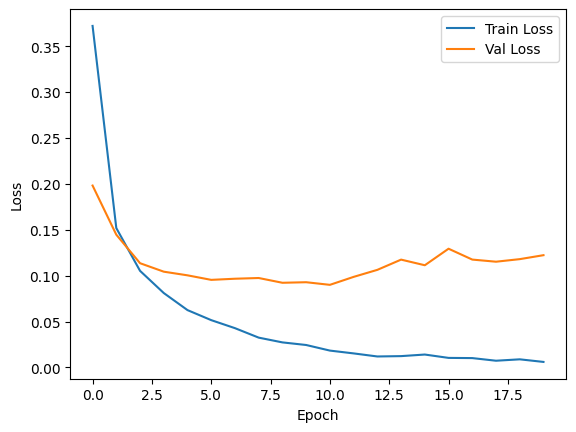

In [14]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Langkah 12 - Eksplorasi


In [15]:
configs = [
    ("Piksel | 128-64 | relu",          "pix", (128, 64),      "relu",    0.0),
    ("Piksel | 128-64 | tanh",          "pix", (128, 64),      "tanh",    0.0),
    ("Piksel | 128-64 | sigmoid",       "pix", (128, 64),      "sigmoid", 0.0),
    ("Piksel | 256-128 | relu",         "pix", (256, 128),     "relu",    0.0),
    ("Piksel | 256-128-64 | relu",      "pix", (256, 128, 64), "relu",    0.0),
    ("Piksel | 256-128 | relu | DO 0.3","pix", (256, 128),     "relu",    0.3),
    ("HOG    | 128-64 | relu",          "hog", (128, 64),      "relu",    0.0),
    ("HOG    | 256-128 | relu | DO 0.3","hog", (256, 128),     "relu",    0.3),
]

data = {
    "pix": (Xp_train, Xp_val, X_test_pix),
    "hog": (Xh_train, Xh_val, X_test_hog_s),
}

results = []
for name, feat, hidden, act, do in configs:
    Xtr, Xva, Xte = data[feat]
    m = build_model(Xtr.shape[1], hidden, act, do)
    m.fit(Xtr, y_train, epochs=20, batch_size=128,
          validation_data=(Xva, y_val), verbose=0)
    _, va = m.evaluate(Xva, y_val, verbose=0)
    _, te = m.evaluate(Xte, y_test, verbose=0)
    results.append((name, va, te))
    print(f"{name:34s} val={va:.4f}  test={te:.4f}")

Piksel | 128-64 | relu             val=0.9748  test=0.9747
Piksel | 128-64 | tanh             val=0.9771  test=0.9775
Piksel | 128-64 | sigmoid          val=0.9759  test=0.9755
Piksel | 256-128 | relu            val=0.9758  test=0.9798
Piksel | 256-128-64 | relu         val=0.9799  test=0.9808
Piksel | 256-128 | relu | DO 0.3   val=0.9811  test=0.9819
HOG    | 128-64 | relu             val=0.9758  test=0.9755
HOG    | 256-128 | relu | DO 0.3   val=0.9801  test=0.9811


In [16]:
import pandas as pd
df_res = pd.DataFrame(results, columns=["Konfigurasi", "Akurasi Validasi", "Akurasi Test"])
df_res = df_res.sort_values("Akurasi Validasi", ascending=False).reset_index(drop=True)
df_res

,Konfigurasi,Akurasi Validasi,Akurasi Test
0,Piksel | 256-128 | relu | DO 0.3,0.981083,0.9819
1,HOG | 256-128 | relu | DO 0.3,0.980083,0.9811
2,Piksel | 256-128-64 | relu,0.979917,0.9808
3,Piksel | 128-64 | tanh,0.977083,0.9775
4,Piksel | 128-64 | sigmoid,0.975917,0.9755
5,HOG | 128-64 | relu,0.975833,0.9755
6,Piksel | 256-128 | relu,0.975750,0.9798
7,Piksel | 128-64 | relu,0.974833,0.9747


In [17]:
best = df_res.iloc[0]
print("Konfigurasi terbaik (berdasarkan validasi):", best["Konfigurasi"])
print("Akurasi validasi:", round(best["Akurasi Validasi"], 4))
print("Akurasi test    :", round(best["Akurasi Test"], 4))

Konfigurasi terbaik (berdasarkan validasi): Piksel | 256-128 | relu | DO 0.3
Akurasi validasi: 0.9811
Akurasi test    : 0.9819


## Langkah 13 - Simpan Model

In [18]:
best_name = df_res.iloc[0]["Konfigurasi"]
best_cfg = next(c for c in configs if c[0] == best_name)
name, feat, hidden, act, do = best_cfg

Xtr, Xva, Xte = data[feat]
final_model = build_model(Xtr.shape[1], hidden, act, do)
final_model.fit(Xtr, y_train, epochs=20, batch_size=128,
                validation_data=(Xva, y_val), verbose=0)

test_loss, test_acc = final_model.evaluate(Xte, y_test, verbose=0)
print("Akurasi test model akhir:", test_acc)

final_model.save('mnist_ann_model.keras')

Akurasi test model akhir: 0.9800000190734863


In [19]:
from google.colab import files
files.download('mnist_ann_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>